# Example: Double-droplet static equilibria

---

The standard FreeGSNKE profile objects describe a **single** plasma: one magnetic axis, one last closed flux surface and one total plasma current.

This notebook shows how to use `freegsnke.droplets.DoubleDroplet` to model **two disjoint plasma droplets**, one above and one below the midplane (here centred at $Z \approx \pm 1$ m in a MAST-U-like tokamak), each enclosed by its own separatrix and carrying its own plasma current.

`DoubleDroplet` wraps two ordinary profile objects (one per droplet). At every evaluation of the current density, and for each droplet independently, it:
1. finds the droplet's magnetic axis (O-point) in its own half of the vessel (above or below `Z_split`),
2. finds the droplet's own separatrix X-point and flood-fills the droplet core from its own axis (falling back to a limiter boundary if the droplet touches the limiter),
3. evaluates that droplet's profile with its own axis flux, boundary flux and plasma current.

The total current density is the sum over droplets, and the composite object can be passed to the static forward and inverse solvers in place of a single-plasma profile.

**Limitations**: static solves only (the time-dependent solvers assume a single plasma), no sub-grid `jtor` refinement, and equilibrium-level diagnostics that assume a single axis/boundary (e.g. `eq.psi_axis`, `eq.psi_bndry`, q-profiles) refer to the *upper* (primary) droplet only. Per-droplet quantities live on `profiles.droplets[k]`.

### Build the machine and the equilibrium object

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from freegsnke import GSstaticsolver, build_machine, equilibrium_update
from freegsnke.droplets import DoubleDroplet
from freegsnke.gradshafranov import Greens
from freegsnke.inverse import Inverse_optimizer
from freegsnke.jtor_update import ConstrainPaxisIp

tokamak = build_machine.tokamak(
    active_coils_path="../machine_configs/MAST-U/MAST-U_like_active_coils.pickle",
    passive_coils_path="../machine_configs/MAST-U/MAST-U_like_passive_coils.pickle",
    limiter_path="../machine_configs/MAST-U/MAST-U_like_limiter.pickle",
    wall_path="../machine_configs/MAST-U/MAST-U_like_wall.pickle",
)

eq = equilibrium_update.Equilibrium(
    tokamak=tokamak, Rmin=0.1, Rmax=2.0, Zmin=-2.2, Zmax=2.2, nx=65, ny=129
)

Active coils --> built from pickle file.
Passive structures --> built from pickle file.
Limiter --> built from pickle file.
Wall --> built from pickle file.


Magnetic probes --> none provided.


Resistance (R) and inductance (M) matrices --> built using actives (and passives if present).
Tokamak built.


### Define the two droplets

Each droplet gets its own profile object, with its own plasma current, pressure and shape parameters. Here we use two `ConstrainPaxisIp` profiles with 100 kA each. `Z_split` is the height separating the regions in which the two magnetic axes are searched for (it does not clip the droplets themselves).

In [2]:
R0, Z0, a = 0.75, 1.0, 0.2  # target droplet centres (R0, +/-Z0) and minor radius [m]
Ip_droplet = 1e5               # current in each droplet [A]

upper = ConstrainPaxisIp(eq, 3e3, Ip_droplet, 0.5, alpha_m=1.8, alpha_n=1.2)
lower = ConstrainPaxisIp(eq, 3e3, Ip_droplet, 0.5, alpha_m=1.8, alpha_n=1.2)
profiles = DoubleDroplet(eq, upper, lower, Z_split=0.0)
print(f"{profiles.n_droplets} droplets, total plasma current {profiles.Ip:.0f} A")

2 droplets, total plasma current 200000 A


### Initial guess for the plasma flux

The default initial guess is a single plasma at the centre of the vessel, so we instead build the flux generated by two Gaussian current blobs at the desired droplet locations.

In [3]:
def droplet_guess(eq, currents, centres, width):
    psi = np.zeros_like(eq.R)
    for Ip, (Rc, Zc) in zip(currents, centres):
        w = np.exp(-((eq.R - Rc) ** 2 + (eq.Z - Zc) ** 2) / width**2)
        w *= eq.limiter_handler.mask_inside_limiter
        w *= Ip / np.sum(w)
        for i, j in zip(*np.nonzero(w > 1e-3 * np.amax(w))):
            psi += w[i, j] * Greens(eq.R[i, j], eq.Z[i, j], eq.R, eq.Z)
    return psi

psi_guess = droplet_guess(eq, [Ip_droplet, Ip_droplet], [(R0, Z0), (R0, -Z0)], width=a / 1.5)
eq.set_plasma_psi(psi_guess)

### Design the coil currents (static inverse solve)

We ask for magnetic nulls at the two droplet axes $(R_0, \pm Z_0)$ and for four isoflux points around each droplet.

Because two small droplets are not confined at all by zero coil currents, the inverse solver is much more robust if it starts from a sensible set of coil currents. We obtain one by solving the *linearised* constraint problem (nulls and isoflux conditions for the guessed plasma flux plus the coils' Green's functions) in a regularised least-squares sense.

In [4]:
# isoflux points around the upper droplet, mirrored for the lower one
# (with force_up_down_symmetric=True the lower points should be listed as the
# exact mirror images of the upper points, in the same order)
upper_points = [(R0 - a, Z0), (R0 + a, Z0), (R0, Z0 + a), (R0, Z0 - a)]
constraint_points = {
    Z0: upper_points,
    -Z0: [(r, -z) for r, z in upper_points],
}
null_points = [[R0, R0], [Z0, -Z0]]
# a single isoflux set: in this up-down symmetric design both droplet
# boundaries are asked to lie on the same flux surface
all_points = constraint_points[Z0] + constraint_points[-Z0]
isoflux_set = [np.array([[r for r, z in all_points], [z for r, z in all_points]])]
constrain = Inverse_optimizer(null_points=null_points, isoflux_set=isoflux_set)

# --- linear least-squares seed for the coil currents ---
from scipy.interpolate import RectBivariateSpline

eq.tokamak["Solenoid"].control = False
eq.tokamak["P6"].control = False
eq.tokamak.set_coil_current("Solenoid", 0.0)
coil_names = list(eq.tokamak.getCurrents())[:12]
seed_coils = [n for n in coil_names if eq.tokamak[n].control]

def interp(field, r, z, dx=0, dy=0):
    return RectBivariateSpline(eq.R_1D, eq.Z_1D, field)(r, z, dx=dx, dy=dy, grid=False)

coil_psi = [eq._vgreen[coil_names.index(n)] for n in seed_coils]
rows, rhs = [], []
for zc in (Z0, -Z0):
    for d in ((1, 0), (0, 1)):  # null: dpsi/dR = dpsi/dZ = 0 at the axis
        rows.append([interp(g, R0, zc, *d) for g in coil_psi])
        rhs.append(-interp(psi_guess, R0, zc, *d))
    ref, *others = constraint_points[zc]  # isoflux: psi(p) = psi(ref)
    for p in others:
        rows.append([interp(g, *p) - interp(g, *ref) for g in coil_psi])
        rhs.append(-(interp(psi_guess, *p) - interp(psi_guess, *ref)))
A, b = np.array(rows), np.array(rhs)
scale = np.abs(A).max(axis=1, keepdims=True)
A, b = A / scale, b / scale[:, 0]
AtA = A.T @ A
seed = np.linalg.solve(AtA + 1e-4 * np.trace(AtA) / len(seed_coils) * np.eye(len(seed_coils)), A.T @ b)
for name, current in zip(seed_coils, seed):
    eq.tokamak.set_coil_current(name, float(current))

# --- full nonlinear inverse solve ---
GSStaticSolver = GSstaticsolver.NKGSsolver(eq)
GSStaticSolver.solve(
    eq=eq,
    profiles=profiles,
    constrain=constrain,
    target_relative_tolerance=1e-4,
    force_up_down_symmetric=True,
)
GSStaticSolver.forward_solve(eq, profiles, target_relative_tolerance=1e-8)

Inverse static solve SUCCESS. Tolerance 1.93e-05 (vs. requested 0.0001) reached in 20/100 iterations.
Forward static solve SUCCESS. Tolerance 3.24e-09 (vs. requested 1.00e-08) reached in 3/100 iterations.


### Inspect the droplets

Each sub-profile in `profiles.droplets` holds its own axis, separatrix X-point, boundary flux, core mask and current density.

In [5]:
for name, p in zip(["upper", "lower"], profiles.droplets):
    print(
        f"{name}: axis (R, Z) = ({p.opt[0, 0]:.3f}, {p.opt[0, 1]:.3f}) m, "
        f"X-point (R, Z) = ({p.xpt[0, 0]:.3f}, {p.xpt[0, 1]:.3f}) m, "
        f"limited = {p.flag_limiter}, Ip = {np.sum(p.jtor) * profiles.dRdZ:.0f} A"
    )
print("Total plasma current:", eq.plasmaCurrent())
print("Designed coil currents [A]:", {n: round(eq.tokamak[n].current) for n in coil_names})

upper: axis (R, Z) = (0.929, 0.888) m, X-point (R, Z) = (1.181, 0.937) m, limited = False, Ip = 100000 A
lower: axis (R, Z) = (0.929, -0.888) m, X-point (R, Z) = (1.181, -0.937) m, limited = False, Ip = 100000 A
Total plasma current: 200000.0
Designed coil currents [A]: {'Solenoid': 0, 'PX': -6651, 'D1': 25891, 'D2': 13444, 'D3': 4307, 'Dp': -12761, 'D5': -269, 'D6': -7062, 'D7': -555, 'P4': 8746, 'P5': -6114, 'P6': 0}


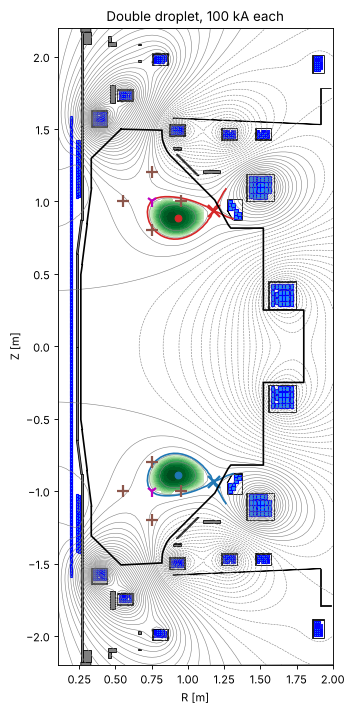

In [6]:
def plot_droplets(eq, profiles, ax, title=""):
    ax.contour(eq.R, eq.Z, eq.psi(), 60, colors="grey", linewidths=0.5)
    jtor = np.where(profiles.jtor != 0, profiles.jtor, np.nan)
    ax.contourf(eq.R, eq.Z, jtor, 20, cmap="Greens")
    for p, c in zip(profiles.droplets, ["tab:red", "tab:blue"]):
        # separatrix of each droplet: its own boundary flux, drawn near its core only
        dist = np.hypot(eq.R - p.opt[0, 0], eq.Z - p.opt[0, 1])
        near = np.where(dist < 0.4, eq.psi(), np.nan)
        ax.contour(eq.R, eq.Z, near, [p.psi_bndry], colors=c)
        ax.plot(*p.opt[0, :2], "o", color=c)
        if len(p.xpt):
            ax.plot(*p.xpt[0, :2], "x", color=c, ms=10, mew=2)
    eq.tokamak.plot(axis=ax, show=False)
    ax.plot(eq.tokamak.limiter.R, eq.tokamak.limiter.Z, "k", lw=1.5)
    ax.set_xlim(0.1, 2.0); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal")
    ax.set_xlabel("R [m]"); ax.set_ylabel("Z [m]"); ax.set_title(title)

fig, ax = plt.subplots(figsize=(5, 9), dpi=80)
plot_droplets(eq, profiles, ax, "Double droplet, 100 kA each")
constrain.plot(axis=ax, show=False)
plt.tight_layout()

### Forward solve with unequal droplet currents

Keeping the coil currents designed above, each droplet carries whatever current its own profile prescribes: here the upper droplet carries 110 kA and the lower one 90 kA.

Forward static solve DID NOT CONVERGE. Tolerance 1.26e-01 (vs. requested 1.00e-08) reached in 100/100 iterations.
Droplet currents [A]: [110000.  90000.]


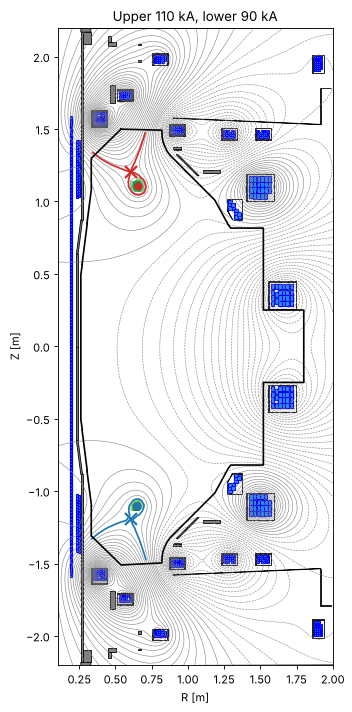

In [7]:
upper2 = ConstrainPaxisIp(eq, 3e3, 1.1e5, 0.5, alpha_m=1.8, alpha_n=1.2)
lower2 = ConstrainPaxisIp(eq, 3e3, 0.9e5, 0.5, alpha_m=1.8, alpha_n=1.2)
profiles2 = DoubleDroplet(eq, upper2, lower2, Z_split=0.0)

# same coil currents; restart from a guess with the new droplet currents
# (static GS solutions are not unique, so a reasonable starting point matters)
eq2 = eq.create_auxiliary_equilibrium()
eq2.set_plasma_psi(droplet_guess(eq2, [1.1e5, 0.9e5], [(R0, Z0), (R0, -Z0)], width=a / 1.5))
GSStaticSolver.forward_solve(eq2, profiles2, target_relative_tolerance=1e-8)
print("Droplet currents [A]:", profiles2.droplet_currents())

fig, ax = plt.subplots(figsize=(5, 9), dpi=80)
plot_droplets(eq2, profiles2, ax, "Upper 110 kA, lower 90 kA")
plt.tight_layout()

### Larger, shaped droplets

The droplets above are small. Larger droplets need a more careful coil design: here we load a stored design with **400 kA per droplet**, about **0.38 m² per droplet**, elongation $\kappa \approx 1.56$ and triangularity $\delta \approx 0.58$ on the X-point side. Both droplets remain diverted (each bounded by its own X-point, well inside the limiter).

This design was obtained in steps: an inverse solve with elliptical isoflux targets gave large but limited droplets; the coil currents were then adjusted with a Gauss-Newton iteration on forward solves (finite-difference sensitivities of the X-point and axis positions, and of the droplets' elongation, triangularity and area, with respect to the coil currents) until the droplets became diverted, and then until they were elongated. Static GS solutions are not unique, so the stored plasma flux is used as the starting point of the forward solve, to land on the same solution.

Note that with this coil set the triangularity on the side of each droplet facing the midplane stays close to zero: the only coil at the inboard midplane is the solenoid, and the facing side of each droplet is flattened by the other droplet's current.

In [8]:
data = np.load("data/double_droplet_SH3.npz")
Rmin, Rmax, Zmin, Zmax, nx, ny = data["grid"]
eq3 = equilibrium_update.Equilibrium(
    tokamak=tokamak, Rmin=Rmin, Rmax=Rmax, Zmin=Zmin, Zmax=Zmax, nx=int(nx), ny=int(ny)
)
for name, current in zip(data["coil_names"], data["coil_currents"]):
    eq3.tokamak.set_coil_current(str(name), float(current))
eq3.set_plasma_psi(data["plasma_psi"])

paxis, Ip3, fvac, alpha_m, alpha_n = data["profile"]
profiles3 = DoubleDroplet(
    eq3,
    ConstrainPaxisIp(eq3, paxis, Ip3, fvac, alpha_m=alpha_m, alpha_n=alpha_n),
    ConstrainPaxisIp(eq3, paxis, Ip3, fvac, alpha_m=alpha_m, alpha_n=alpha_n),
)
GSstaticsolver.NKGSsolver(eq3).forward_solve(eq3, profiles3, target_relative_tolerance=1e-8)
print("Coil currents [A]:", {str(n): round(float(c)) for n, c in zip(data["coil_names"], data["coil_currents"])})

Forward static solve SUCCESS. Tolerance 5.63e-09 (vs. requested 1.00e-08) reached in 0/100 iterations.
Coil currents [A]: {'Solenoid': 10590, 'PX': 21405, 'D1': 19900, 'D2': -17653, 'D3': -19807, 'Dp': 45072, 'D5': -174, 'D6': -53586, 'D7': -21908, 'P4': 29745, 'P5': -5828, 'P6': 0}


upper: axis (0.87, +0.57) m, kappa = 1.56, delta_upper = 0.58, delta_lower = -0.04, area = 0.37 m^2, diverted
lower: axis (0.87, -0.57) m, kappa = 1.56, delta_upper = -0.04, delta_lower = 0.58, area = 0.37 m^2, diverted


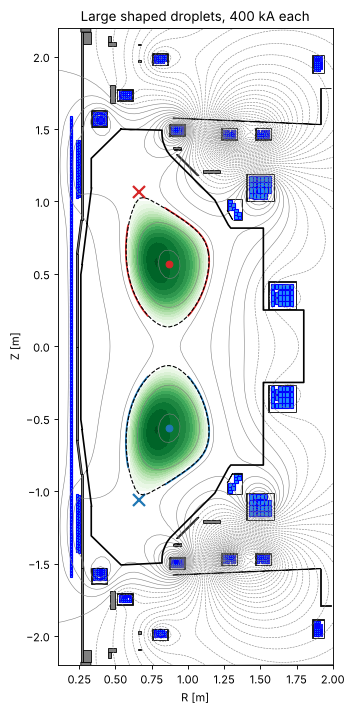

In [9]:
from skimage import measure
from matplotlib.path import Path as MplPath

def flux_surface(eq, droplet, psin=0.99):
    """The psi_N = psin flux surface of a droplet, as (R, Z) arrays."""
    level = droplet.psi_axis + psin * (droplet.psi_bndry - droplet.psi_axis)
    dR, dZ = eq.R_1D[1] - eq.R_1D[0], eq.Z_1D[1] - eq.Z_1D[0]
    for c in sorted(measure.find_contours(eq.psi(), level), key=len):
        R, Z = eq.R_1D[0] + c[:, 0] * dR, eq.Z_1D[0] + c[:, 1] * dZ
        if len(R) > 10 and MplPath(np.c_[R, Z]).contains_point(droplet.opt[0, :2]):
            return R, Z

def shape(R, Z):
    """Elongation and triangularity (upper/lower) of a closed flux surface."""
    Rgeo, a = (R.max() + R.min()) / 2, (R.max() - R.min()) / 2
    return dict(
        kappa=(Z.max() - Z.min()) / (2 * a),
        delta_upper=(Rgeo - R[np.argmax(Z)]) / a,
        delta_lower=(Rgeo - R[np.argmin(Z)]) / a,
        area=0.5 * abs(np.dot(R, np.roll(Z, 1)) - np.dot(Z, np.roll(R, 1))),
    )

fig, ax = plt.subplots(figsize=(5, 9), dpi=80)
plot_droplets(eq3, profiles3, ax, "Large shaped droplets, 400 kA each")
for name, p in zip(["upper", "lower"], profiles3.droplets):
    R, Z = flux_surface(eq3, p)
    ax.plot(R, Z, "k--", lw=1)
    m = shape(R, Z)
    print(
        f"{name}: axis ({p.opt[0, 0]:.2f}, {p.opt[0, 1]:+.2f}) m, "
        f"kappa = {m['kappa']:.2f}, delta_upper = {m['delta_upper']:.2f}, "
        f"delta_lower = {m['delta_lower']:.2f}, area = {m['area']:.2f} m^2, "
        f"{'limited' if p.flag_limiter else 'diverted'}"
    )
plt.tight_layout()